# Questão 13 - Ensaio sobre a arquitetura Transformer

## 1. Introdução

O Transformer é uma arquitetura de rede neural apresentada em 2017 no artigo "Attention is all you need", de Vaswani e outros autores. Ela foi criada para tradução automática e hoje é a base dos grandes modelos de linguagem, como GPT, BERT e Claude.

Antes dele, os modelos de texto mais usados eram as redes recorrentes. Elas leem a frase uma palavra por vez, da esquerda para a direita. Isso traz dois problemas: o treino é lento, porque não dá para processar as palavras em paralelo, e a rede tem dificuldade para ligar palavras que estão longe uma da outra.

O Transformer resolve os dois problemas com uma ideia: a atenção. Cada palavra olha diretamente para todas as outras palavras da frase e decide quais são importantes para ela. Como não há leitura em sequência, todas as palavras são processadas ao mesmo tempo.

Este ensaio explica os conceitos principais e depois mostra o funcionamento passo a passo com um exemplo: a tradução da frase "I love India" para o espanhol, "Me encanta la India". O exemplo e os números da seção de atenção seguem o vídeo indicado na questão. Os cálculos são feitos em numpy para que cada etapa possa ser conferida.

## 2. Visão geral

O Transformer original tem duas partes.

**Encoder (codificador):** lê a frase de entrada inteira de uma vez e produz, para cada palavra, um vetor que representa o seu significado naquele contexto.

**Decoder (decodificador):** escreve a frase de saída uma palavra por vez. A cada passo ele olha para o que já escreveu e para os vetores produzidos pelo encoder, e escolhe a próxima palavra.

A partir dessa arquitetura surgiram três famílias de modelos.

**Só encoder:** como o BERT. Cada palavra pode olhar para a esquerda e para a direita. É usado em tarefas de compreensão, como classificar um texto ou buscar frases parecidas.

**Só decoder:** como os modelos GPT. Cada palavra só pode olhar para trás. É usado para gerar texto.

**Encoder e decoder:** como o Transformer original e o T5. É usado quando há uma entrada e uma saída bem definidas, como em tradução e resumo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(7)

## 3. Da palavra ao vetor

**Tokenização**

O computador não trabalha com palavras. O primeiro passo é quebrar o texto em tokens, que são pedaços de texto, e trocar cada token por um número. Nos modelos reais um token pode ser uma palavra inteira ou parte de uma palavra, e o vocabulário tem dezenas de milhares de itens. Aqui cada palavra é um token.

A frase de saída ganha dois tokens especiais: um que marca o início e outro que marca o fim.

In [2]:
vocab_entrada = ["I", "love", "India"]
vocab_saida = ["<inicio>", "Me", "encanta", "la", "India", "<fim>"]

frase = ["I", "love", "India"]
ids_entrada = [vocab_entrada.index(t) for t in frase]
print("Tokens:", frase)
print("IDs:   ", ids_entrada)

Tokens: ['I', 'love', 'India']
IDs:    [0, 1, 2]


**Embedding**

Cada ID é trocado por um vetor de números, chamado embedding. Os embeddings ficam em uma tabela com uma linha por token. Os valores dessa tabela são aprendidos no treino, e o resultado é que palavras com significado parecido ficam com vetores parecidos.

Neste exemplo cada vetor tem 16 números. O artigo original usa 512.

In [3]:
D = 16
emb_entrada = rng.normal(0, 1, (len(vocab_entrada), D))
emb_saida = rng.normal(0, 1, (len(vocab_saida), D))

x = emb_entrada[ids_entrada]
print("Formato:", x.shape, "(3 tokens, 16 números cada)")
print("Vetor de 'love':", x[1])

Formato: (3, 16) (3 tokens, 16 números cada)
Vetor de 'love': [-1.34 -0.46 -1.9  -1.29 -1.84 -0.24 -1.27  0.27  0.16 -0.19 -2.52 -0.54
 -0.05  0.11 -1.53 -0.48]


**Codificação posicional**

A atenção olha para todas as palavras ao mesmo tempo e, sozinha, não sabe a ordem delas. "Dog bites man" e "man bites dog" teriam a mesma representação. Para resolver isso, soma-se ao embedding de cada token um vetor que depende só da posição dele na frase.

O artigo original usa senos e cossenos de frequências diferentes. Cada posição recebe um padrão único e posições vizinhas recebem padrões parecidos.

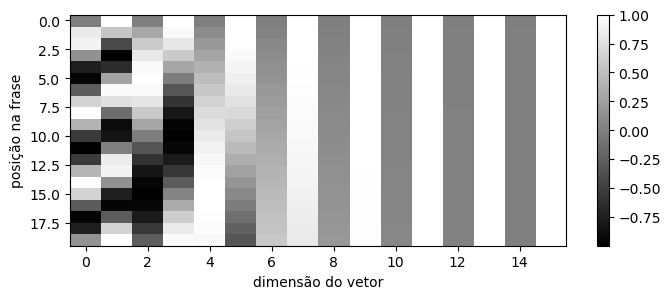

In [4]:
def codificacao_posicional(n, d):
    pos = np.arange(n)[:, None]
    i = np.arange(0, d, 2)[None, :]
    angulo = pos / 10000 ** (i / d)
    pe = np.zeros((n, d))
    pe[:, 0::2] = np.sin(angulo)
    pe[:, 1::2] = np.cos(angulo)
    return pe


plt.figure(figsize=(8, 3))
plt.imshow(codificacao_posicional(20, D), aspect="auto", cmap="gray")
plt.xlabel("dimensão do vetor")
plt.ylabel("posição na frase")
plt.colorbar()
plt.show()

x = x + codificacao_posicional(len(frase), D)

## 4. Atenção

A atenção é a parte central do Transformer. Uma forma de entender é pensar em uma biblioteca. Quem procura um livro tem uma pergunta (query). Cada livro tem uma etiqueta (key) e um conteúdo (value). A pessoa compara a pergunta com as etiquetas e lê mais os livros cujas etiquetas combinam melhor.

No Transformer, cada token gera três vetores: query, key e value. Eles são obtidos multiplicando o vetor do token por três matrizes de pesos aprendidas no treino.

A conta completa é:

**Atenção(Q, K, V) = softmax(Q Kᵀ / √dk) V**

Ela tem quatro passos.

Passo 1: comparar a query com cada key pelo produto escalar. Um valor alto indica que as duas combinam.

Passo 2: dividir pela raiz de dk, o tamanho dos vetores. Com vetores longos os produtos ficam muito grandes e o softmax fica extremo, o que atrapalha o treino. A divisão mantém os números em uma faixa estável.

Passo 3: aplicar o softmax, que transforma as pontuações em pesos positivos que somam 1.

Passo 4: fazer a média dos values usando esses pesos.

In [5]:
def softmax(z, eixo=-1):
    e = np.exp(z - z.max(axis=eixo, keepdims=True))
    return e / e.sum(axis=eixo, keepdims=True)


def atencao(Q, K, V, mascara=None):
    pontos = Q @ K.T / np.sqrt(K.shape[-1])
    if mascara is not None:
        pontos = np.where(mascara, pontos, -1e9)
    pesos = softmax(pontos)
    return pesos @ V, pesos

**Exemplo com números**

O vídeo usa vetores de tamanho 2. A query é [1, 0]. A key 1 é [1, 0] e a key 2 é [0, 1]. O value 1 é [2, 0] e o value 2 é [0, 2]. São números escolhidos para ilustrar, não vieram de um modelo treinado.

In [6]:
Q = np.array([[1.0, 0.0]])
K = np.array([[1.0, 0.0], [0.0, 1.0]])
V = np.array([[2.0, 0.0], [0.0, 2.0]])

pontos = Q @ K.T
escalados = pontos / np.sqrt(2)
pesos = softmax(escalados)
saida = pesos @ V

print("Passo 1, produto escalar:   ", pontos[0])
print("Passo 2, dividir por 1,41:  ", escalados[0])
print("Passo 3, softmax (pesos):   ", pesos[0])
print("Passo 4, média dos values:  ", saida[0])

Passo 1, produto escalar:    [1. 0.]
Passo 2, dividir por 1,41:   [0.71 0.  ]
Passo 3, softmax (pesos):    [0.67 0.33]
Passo 4, média dos values:   [1.34 0.66]


A query combina com a key 1 (pontuação 1) e não combina com a key 2 (pontuação 0). Depois do softmax, o primeiro value recebe peso 0,67 e o segundo 0,33. A saída é [1,34 0,66]: dois terços do value 1 e um terço do value 2. O resultado é o mesmo do vídeo.

**Autoatenção na frase**

Na autoatenção, queries, keys e values vêm todos da mesma frase. Cada token consulta todos os outros, inclusive ele mesmo. O exemplo clássico é a frase "The animal didn't cross the road because it was tired". Um modelo treinado aprende a ligar "it" a "animal" e não a "road". Ninguém programa essa regra, ela é aprendida dos dados.

Abaixo a autoatenção é aplicada à frase "I love India". As matrizes de pesos são aleatórias, porque o modelo não foi treinado, então os valores não têm significado linguístico. O que importa é a forma: cada linha mostra como um token distribui sua atenção e soma 1.

In [7]:
Wq, Wk, Wv = (rng.normal(0, 0.5, (D, D)) for _ in range(3))
_, pesos_frase = atencao(x @ Wq, x @ Wk, x @ Wv)
pd.DataFrame(pesos_frase, index=frase, columns=frase).round(2)

,I,love,India
I,0.12,0.23,0.65
love,0.00,0.16,0.84
India,0.08,0.90,0.03


**Atenção com várias cabeças**

Uma única atenção olha para a frase de um jeito só. O Transformer usa várias em paralelo, cada uma com suas próprias matrizes. São as cabeças de atenção. Cada cabeça pode aprender um tipo de relação: uma liga o verbo ao sujeito, outra liga o pronome ao nome a que ele se refere. As saídas das cabeças são juntadas e passam por mais uma matriz. O artigo original usa 8 cabeças. Aqui são 2.

In [8]:
N_CABECAS = 2


def nova_atencao():
    dk = D // N_CABECAS
    return {
        "Wq": rng.normal(0, 0.5, (N_CABECAS, D, dk)),
        "Wk": rng.normal(0, 0.5, (N_CABECAS, D, dk)),
        "Wv": rng.normal(0, 0.5, (N_CABECAS, D, dk)),
        "Wo": rng.normal(0, 0.5, (D, D)),
    }


def multi_cabecas(p, consulta, fonte, mascara=None):
    saidas, pesos = [], []
    for c in range(N_CABECAS):
        s, w = atencao(consulta @ p["Wq"][c], fonte @ p["Wk"][c], fonte @ p["Wv"][c], mascara)
        saidas.append(s)
        pesos.append(w)
    return np.concatenate(saidas, axis=-1) @ p["Wo"], pesos

## 5. O encoder

O encoder é uma pilha de camadas iguais. O artigo original usa 6. Cada camada faz quatro coisas.

**Autoatenção:** os tokens trocam informação entre si.

**Soma e normalização:** a entrada da autoatenção é somada à saída (conexão residual) e o resultado é normalizado. A soma garante que a informação original não se perde. A normalização mantém os números em uma faixa saudável.

**Rede feed-forward:** uma pequena rede de duas camadas aplicada a cada token separadamente.

**Soma e normalização:** de novo.

Ao final da pilha, cada token tem um vetor que carrega o seu significado dentro daquela frase.

In [9]:
def normalizar(v):
    return (v - v.mean(axis=-1, keepdims=True)) / (v.std(axis=-1, keepdims=True) + 1e-6)


def nova_ff():
    return {"W1": rng.normal(0, 0.5, (D, 4 * D)), "W2": rng.normal(0, 0.5, (4 * D, D))}


def feed_forward(p, v):
    return np.maximum(0, v @ p["W1"]) @ p["W2"]


def camada_encoder(p, v):
    att, _ = multi_cabecas(p["att"], v, v)
    v = normalizar(v + att)
    return normalizar(v + feed_forward(p["ff"], v))


encoder = {"att": nova_atencao(), "ff": nova_ff()}
memoria = camada_encoder(encoder, x)
print("Saída do encoder:", memoria.shape, "(um vetor de contexto para cada token de entrada)")

Saída do encoder: (3, 16) (um vetor de contexto para cada token de entrada)


## 6. O decoder

Cada camada do decoder original tem três partes, cada uma seguida de soma e normalização.

**Autoatenção com máscara:** o decoder olha para as palavras que já escreveu. Ao prever uma palavra, ele só pode ver as anteriores. As posições futuras recebem menos infinito antes do softmax e ficam com peso zero. Essa é a máscara causal. Ela é necessária porque, na hora de gerar, o futuro ainda não existe. Se o decoder pudesse espiar o futuro no treino, aprenderia a colar.

**Atenção cruzada:** é como o decoder consulta o encoder. As queries vêm do decoder e as keys e os values vêm da saída do encoder. É aqui que a frase de saída se liga à frase de entrada.

**Rede feed-forward:** igual à do encoder.

Os modelos só com decoder, como o GPT, não têm encoder e por isso não têm atenção cruzada. O prompt e a resposta formam uma sequência só, lida com autoatenção mascarada.

In [10]:
def camada_decoder(p, y, memoria):
    n = len(y)
    mascara = np.tril(np.ones((n, n), dtype=bool))
    att, pesos_proprios = multi_cabecas(p["att"], y, y, mascara)
    y = normalizar(y + att)
    cruz, pesos_cruzados = multi_cabecas(p["cruzada"], y, memoria)
    y = normalizar(y + cruz)
    return normalizar(y + feed_forward(p["ff"], y)), pesos_proprios, pesos_cruzados


def rodar_decoder(tokens):
    ids = [vocab_saida.index(t) for t in tokens]
    y = emb_saida[ids] + codificacao_posicional(len(ids), D)
    return camada_decoder(decoder, y, memoria)


decoder = {"att": nova_atencao(), "cruzada": nova_atencao(), "ff": nova_ff()}
entrada_decoder = ["<inicio>", "Me", "encanta", "la", "India"]
h, pesos_proprios, pesos_cruzados = rodar_decoder(entrada_decoder)

A tabela mostra os pesos da autoatenção mascarada (primeira cabeça). A parte acima da diagonal é toda zero: nenhum token olha para os que vêm depois dele.

In [11]:
pd.DataFrame(pesos_proprios[0], index=entrada_decoder, columns=entrada_decoder).round(2)

,<inicio>,Me,encanta,la,India
<inicio>,1.00,0.00,0.00,0.00,0.0
Me,0.01,0.99,0.00,0.00,0.0
encanta,0.06,0.02,0.92,0.00,0.0
la,0.97,0.00,0.02,0.01,0.0
India,0.88,0.00,0.00,0.12,0.0


Na atenção cruzada, cada token da saída distribui sua atenção entre os três tokens da entrada.

In [12]:
pd.DataFrame(pesos_cruzados[0], index=entrada_decoder, columns=frase).round(2)

,I,love,India
<inicio>,0.67,0.30,0.04
Me,0.04,0.17,0.80
encanta,0.02,0.08,0.91
la,0.56,0.32,0.12
India,0.58,0.30,0.12


## 7. Da saída do decoder à próxima palavra

O vetor que sai do decoder passa por uma camada linear que produz uma pontuação para cada palavra do vocabulário. O softmax transforma essas pontuações em probabilidades e a palavra mais provável é escolhida.

É importante não confundir os dois tipos de número. Os pesos de atenção dizem para onde olhar. As probabilidades de saída dizem qual é a próxima palavra.

**Treino**

No treino usa-se uma técnica chamada teacher forcing. O decoder recebe a resposta correta deslocada uma posição para a direita e prevê todas as posições de uma vez. A máscara impede que ele veja a resposta da posição que está prevendo.

Para o exemplo ficar completo, a camada linear de saída é treinada abaixo com descida de gradiente. Só essa última camada é treinada, o resto do modelo continua com pesos aleatórios, e o treino usa uma única frase. Isso serve apenas para demonstrar o mecanismo. Um modelo real treina todas as camadas com milhões de frases.

In [13]:
alvo = ["Me", "encanta", "la", "India", "<fim>"]
pd.DataFrame({"entrada do decoder": entrada_decoder, "palavra a prever": alvo})

,entrada do decoder,palavra a prever
0,<inicio>,Me
1,Me,encanta
2,encanta,la
3,la,India
4,India,<fim>


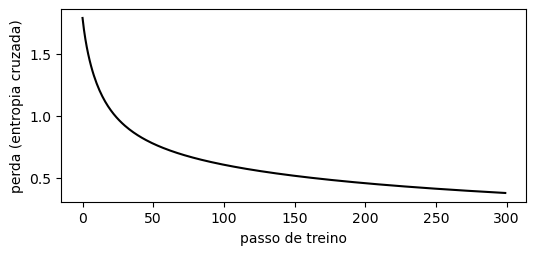

In [14]:
ids_alvo = np.array([vocab_saida.index(t) for t in alvo])
Y = np.eye(len(vocab_saida))[ids_alvo]
W_saida = np.zeros((D, len(vocab_saida)))

perdas = []
for _ in range(300):
    prob = softmax(h @ W_saida)
    perdas.append(-np.log(prob[np.arange(len(alvo)), ids_alvo]).mean())
    W_saida -= 0.1 * h.T @ (prob - Y) / len(alvo)

plt.figure(figsize=(6, 2.5))
plt.plot(perdas, color="black")
plt.xlabel("passo de treino")
plt.ylabel("perda (entropia cruzada)")
plt.show()

**Geração**

Na geração não existe resposta correta para consultar. O decoder começa só com o token de início e trabalha em ciclo: prevê uma palavra, coloca essa palavra na própria entrada e prevê a próxima. O ciclo termina quando sai o token de fim.

In [15]:
gerado = ["<inicio>"]
passos = []
while gerado[-1] != "<fim>" and len(gerado) < 10:
    h_atual, _, _ = rodar_decoder(gerado)
    prob = softmax(h_atual[-1] @ W_saida)
    melhores = np.argsort(prob)[::-1][:3]
    passos.append({
        "entrada do decoder": " ".join(gerado),
        "palavra escolhida": vocab_saida[melhores[0]],
        "probabilidades": ", ".join(f"{vocab_saida[i]} {prob[i]:.2f}" for i in melhores),
    })
    gerado.append(vocab_saida[melhores[0]])

pd.set_option("display.max_colwidth", None)
pd.DataFrame(passos)

,entrada do decoder,palavra escolhida,probabilidades
0,<inicio>,Me,"Me 0.68, India 0.21, <fim> 0.09"
1,<inicio> Me,encanta,"encanta 0.95, la 0.04, Me 0.01"
2,<inicio> Me encanta,la,"la 0.93, encanta 0.04, India 0.02"
3,<inicio> Me encanta la,India,"India 0.45, <fim> 0.33, Me 0.20"
4,<inicio> Me encanta la India,<fim>,"<fim> 0.57, India 0.32, Me 0.10"


In [16]:
print("Entrada:", " ".join(frase))
print("Saída:  ", " ".join(gerado[1:-1]))

Entrada: I love India
Saída:   Me encanta la India


O modelo escreve "Me", coloca "Me" na entrada, escreve "encanta", e assim por diante até o token de fim. A cada passo o decoder inteiro roda de novo sobre tudo o que já foi escrito. Esse modo de gerar, uma palavra por vez usando as anteriores, é chamado de autorregressivo.

## 8. Resumo do caminho completo

Juntando as etapas para a frase "I love India":

A frase é quebrada em tokens e cada token vira um ID.

Cada ID vira um vetor (embedding) e recebe a codificação da sua posição.

O encoder aplica autoatenção e a rede feed-forward, com soma e normalização, e entrega um vetor de contexto por token.

O decoder começa com o token de início. Ele aplica autoatenção mascarada sobre o que já escreveu, atenção cruzada sobre a saída do encoder e a rede feed-forward.

A camada linear e o softmax dão a probabilidade de cada palavra. A mais provável é escolhida e volta para a entrada do decoder.

O ciclo se repete até o token de fim: "Me encanta la India".

## 9. Por que a arquitetura deu certo

O primeiro motivo é o paralelismo. Como a atenção processa todos os tokens de uma vez, o treino aproveita bem as placas de vídeo. Isso permitiu treinar modelos muito maiores com muito mais texto.

O segundo motivo é o alcance. Qualquer token se liga a qualquer outro em um único passo, não importa a distância entre eles.

O terceiro motivo é a generalidade. A mesma arquitetura funciona para texto, imagem, áudio e código, mudando só a forma de criar os tokens.

O principal custo é que a atenção compara cada token com todos os outros. O número de comparações cresce com o quadrado do tamanho da sequência, o que limita o tamanho do contexto e encarece textos longos.

## 10. Considerações finais

A ideia central do Transformer é simples: deixar cada palavra consultar as outras e combinar o que encontrou. O restante da arquitetura existe para fazer essa ideia funcionar em escala: a codificação posicional devolve a ordem das palavras, as várias cabeças permitem olhar a frase de formas diferentes, as conexões residuais e a normalização tornam possível empilhar muitas camadas, e a máscara causal permite gerar texto.

O exemplo deste notebook usa pesos aleatórios e uma única frase, então ele mostra o mecanismo e não a qualidade de um modelo real. Ainda assim, as contas são as mesmas que um modelo de linguagem grande executa. A diferença está na escala: bilhões de pesos em vez de algumas centenas, e pesos aprendidos em vez de sorteados.

## Referências

IMPLEMENTITATAI. Encoders vs decoders explained: how transformers really work (with real attention math). [S. l.: s. n.], 2026. 1 vídeo (9 min). Disponível em: https://youtu.be/bVVm68KTD2M. Acesso em: 11 nov. 2026.

VASWANI, Ashish et al. Attention is all you need. In: ADVANCES IN NEURAL INFORMATION PROCESSING SYSTEMS, 30., 2017, Long Beach. Proceedings [...]. Red Hook: Curran Associates, 2017. p. 5998-6008.